In [1]:
import cobra
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import sys
sys.path.append('../../')
from helper_function import *
cobra.Configuration.solver = 'glpk'

In [2]:
with open('../../Coarse_graining_result/clustered_nodes_c20_s44_pq1_relabeled.pkl', 'rb') as f:
    cluster_nodes = pickle.load(f)
gem2seed = pd.read_csv('../../Expression_datasets/model_reaction_to_seed_reaction_mapping.csv')

In [3]:
OD = pd.read_excel('../../Expression_datasets/harris_nm/harriswang_nbt_cleaned.xlsx', sheet_name='OD')
expression_data = pd.read_excel('../../Expression_datasets/harris_nm/harriswang_nbt_cleaned.xlsx', sheet_name='Expression_data')

In [4]:
def species_gpr_construction(model):
    species_gpr = []
    for rec in model.reactions:
        if len(rec.genes) > 0:
            gene_id = [gene.id for gene in list(rec.genes) if gene.id not in ['Unknown']]
            species_gpr.append((rec.id.split('_')[:-1][0], gene_id))
    species_gpr = pd.DataFrame(species_gpr, columns=['Model_Reaction_ID', 'Gene_IDs'])

    return species_gpr

In [5]:
def species_clustergenes_construction(species_gpr):
    cluster_genes = {}
    for idx, group in cluster_nodes.items():
        for rec in group:
            rec2seed = gem2seed[gem2seed['Model_Reaction_ID'] == rec[:-4]]['SEED_Reaction_ID'].values
            rec2seed = rec2seed[0] if len(rec2seed) > 0 else None
            if rec2seed is not None:
                rec2gene = species_gpr[species_gpr['Model_Reaction_ID'] == rec2seed]['Gene_IDs'].values
                rec2gene = rec2gene[0] if len(rec2gene) > 0 else None
                if rec2gene is not None:
                    if idx not in cluster_genes:
                        cluster_genes[idx] = []
                    for gene in rec2gene:
                        cluster_genes[idx].append(gene)

    return cluster_genes

In [6]:
def species_ei_construction(species_trans_data, cluster_genes):
    n_samples = len(OD.columns) - 1
    overall_value = np.zeros((len(cluster_nodes), n_samples)) 

    for idx, group in cluster_genes.items():

        group_value = np.zeros(n_samples)

        for gene in group:
            gene_count = sum(gene in g for g in cluster_genes.values())

            gene_value = species_trans_data[species_trans_data['geneID'] == gene].iloc[:, 7:].values

            if gene_value.size == 0:
                continue

            gene_value = np.array(gene_value[0]) / gene_count

            group_value += gene_value

        overall_value[idx, :] = group_value

    norm_overall_value = overall_value / np.sum(overall_value, axis=0)

    return norm_overall_value, overall_value

def species_sector_entropy_construction(species_trans_data, cluster_genes):
    n_samples = len(OD.columns) - 1
    overall_entropy = np.zeros((len(cluster_nodes), n_samples)) 


    for idx, group in cluster_genes.items():

        group_entropy = np.zeros(n_samples)

        temp = []

        for gene in group:
            gene_count = sum(gene in g for g in cluster_genes.values())

            gene_value = species_trans_data[species_trans_data['geneID'] == gene].iloc[:, 7:].values

            if gene_value.size == 0:
                continue

            gene_value = np.array(gene_value[0]) / gene_count
            
            temp.append(gene_value)

            temp_array = np.array(temp)

            p = temp_array / np.sum(temp_array, axis=0, keepdims=True)

            group_entropy = -np.sum(p * np.log2(p + 1e-12), axis=0)

        overall_entropy[idx, :] = group_entropy


    return overall_entropy


def species_rec_expression_construction(species_trans_data, cluster_genes, species_gpr, overall_value):
    n_samples = len(OD.columns) - 1
    #overall_value = np.zeros((len(cluster_nodes), n_samples)) 

    rec_expression = {}

    for idx, group in cluster_genes.items():

        temp = {}

        group_value = np.zeros(n_samples)

        for gene in group:
            gene_count = sum(gene in g for g in cluster_genes.values())

            gene_value = species_trans_data[species_trans_data['geneID'] == gene].iloc[:, 7:].values

            if gene_value.size == 0:
                continue

            gene_value = np.array(gene_value[0]) / gene_count / np.sum(overall_value, axis=0)

            rec_seed = [key for key, value in species_gpr.iloc if gene in value]
            rec_name = [gem2seed[gem2seed['SEED_Reaction_ID'] == key]['Model_Reaction_ID'].values[0] for key in rec_seed if key in gem2seed['SEED_Reaction_ID'].values]

            for rec in rec_name:
                if rec not in temp:
                    temp[rec] = np.zeros(n_samples)
                temp[rec] += gene_value / len(rec_name)

        rec_expression[idx] = temp

    return rec_expression

In [7]:
def species_detail_rec_expression_construction(species_trans_data, cluster_genes, species_gpr, overall_value):
    df = []
    for idx, group in cluster_nodes.items():
        for rec in group:
            rec2seed = gem2seed[gem2seed['Model_Reaction_ID'] == rec[:-4]]['SEED_Reaction_ID'].values
            rec2seed = rec2seed[0] if len(rec2seed) > 0 else None
            if rec2seed is not None:
                rec2gene = species_gpr[species_gpr['Model_Reaction_ID'] == rec2seed]['Gene_IDs'].values
                rec2gene = rec2gene[0] if len(rec2gene) > 0 else None
                
                if rec2gene is None:
                    continue
                
                expression = 0
                for gene in rec2gene:
                    gene_count = sum(gene in g for g in cluster_genes.values())

                    gene_value = species_trans_data[species_trans_data['geneID'] == gene].iloc[:, 7:].values

                    if gene_value.size == 0:
                        continue

                    gene_value = np.array(gene_value[0]) / gene_count / np.sum(overall_value, axis=0)

                    expression += gene_value

                df.append((rec, rec2gene, idx, expression))
    return pd.DataFrame(df, columns=['Reaction', 'Gene', 'Cluster', 'Expression'])

In [8]:
total_species_id = []
total_species_ei = []
total_species_sector_entropy = []
total_species_etotal = []
total_species_OD = []
total_species_cluster_genes = []
total_species_rec_expression = []
total_species_detail_rec_expression = []

temp = []


for i in range(len(OD)):
    species_id = OD.iloc[i]['Strain']
    species_OD = OD.iloc[i][1:].values #(#samples)

    species_model = cobra.io.read_sbml_model(f'../../Expression_datasets/harris_nm/gem/{species_id}.xml')
    species_gpr = species_gpr_construction(species_model)

    species_cluster_genes = species_clustergenes_construction(species_gpr)

    species_trans_data = expression_data[expression_data['strain'] == species_id]

    species_ei, _ = species_ei_construction(species_trans_data, species_cluster_genes) #(Ei, #samples)

    species_sector_entropy = species_sector_entropy_construction(species_trans_data, species_cluster_genes)

    species_detail_rec_expression = species_detail_rec_expression_construction(species_trans_data, species_cluster_genes, species_gpr, _)

    #species_rec_expression = species_rec_expression_construction(species_trans_data, species_cluster_genes, species_gpr, _)

    total_species_id.append(species_id)
    total_species_ei.append(species_ei)
    total_species_OD.append(species_OD)
    total_species_etotal.append(np.sum(_, axis=0)/1e6)
    total_species_sector_entropy.append(species_sector_entropy)
    total_species_cluster_genes.append(species_cluster_genes)
    total_species_detail_rec_expression.append(species_detail_rec_expression)
    #total_species_rec_expression.append(species_rec_expression)

'' is not a valid SBML 'SId'.
'' is not a valid SBML 'SId'.
'' is not a valid SBML 'SId'.
'' is not a valid SBML 'SId'.
/tmp/ipykernel_17164/2973039626.py:52: RuntimeWarning: invalid value encountered in divide
  p = temp_array / np.sum(temp_array, axis=0, keepdims=True)
'' is not a valid SBML 'SId'.
'' is not a valid SBML 'SId'.
'' is not a valid SBML 'SId'.
'' is not a valid SBML 'SId'.
'' is not a valid SBML 'SId'.
'' is not a valid SBML 'SId'.
'' is not a valid SBML 'SId'.
'' is not a valid SBML 'SId'.
'' is not a valid SBML 'SId'.
'' is not a valid SBML 'SId'.
'' is not a valid SBML 'SId'.
'' is not a valid SBML 'SId'.
'' is not a valid SBML 'SId'.
'' is not a valid SBML 'SId'.


In [9]:
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 12

with open('../../Expression_datasets/harris_nm/total_r_sector_expression.pkl', 'rb') as f:
    total_species_er = pickle.load(f)
    
from scipy.stats import spearmanr

corr_harris = []
                     
for i in range(20):
    corr = spearmanr(np.array([e[:,-1] for e in total_species_ei]).T[i], [e[-1] for e in total_species_OD])
    corr_harris.append((corr.correlation, corr.pvalue))


/home/complicatedz/miniconda3/envs/autopacman/lib/python3.8/site-packages/scipy/stats/_stats_py.py:4916: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  warnings.warn(stats.ConstantInputWarning(warn_msg))


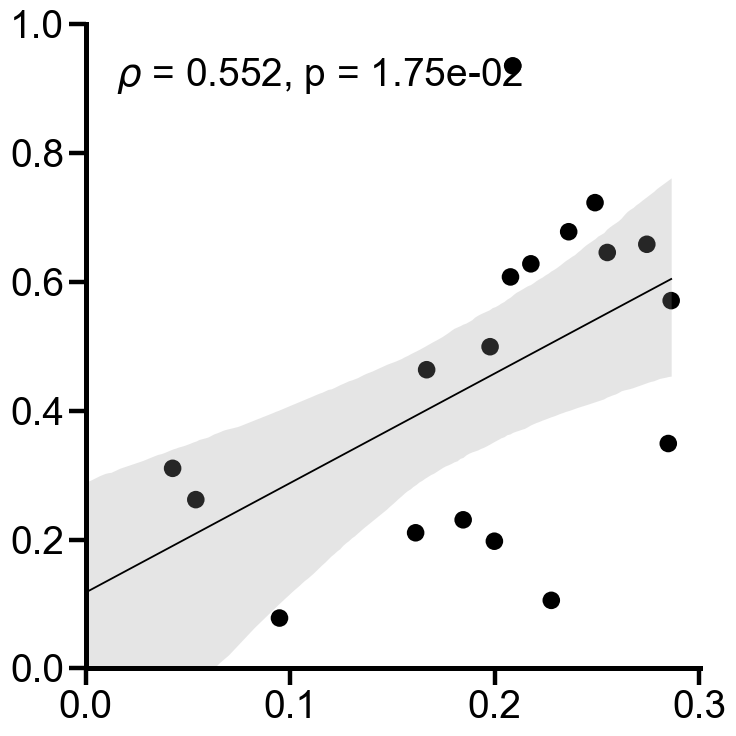

{'rho': 0.5521155830753354,
 'p': 0.01751291469868339,
 'ci_low': 0.18665276329509906,
 'ci_high': 0.7937500000000001,
 'n': 18}

In [10]:
set_panel_style(scale=4)
point_rgb = (0.0, 0.0, 0.0)   # gray
line_rgb  = (0.0, 0.0, 0.0)   # black
band_rgb  = (0.6, 0.6, 0.6)   # gray band

x = np.array([e[-1] for e in total_species_er]).astype(float).astype(float)
#x = np.array([e[-1] for e in total_species_etotal])
y = np.array([e[-1] for e in total_species_OD]).astype(float)

mask = np.isfinite(x) & np.isfinite(y)
x, y = x[mask], y[mask]

# Spearman
rho, p = spearmanr(x, y)

# OLS line + bootstrap CI
m, b = np.polyfit(x, y, deg=1)
xg = np.linspace(0.001, x.max(), 200)
yg = m * xg + b

B = 2000
rng = np.random.default_rng(0)
Yhat = np.empty((B, xg.size))
n = x.size
for i in range(B):
    idx = rng.integers(0, n, n)
    m_i, b_i = np.polyfit(x[idx], y[idx], deg=1)
    Yhat[i] = m_i * xg + b_i
lo, hi = np.percentile(Yhat, [2.5, 97.5], axis=0)

# Plot
fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(
    x, y,
    s=160,
    color=point_rgb,
    edgecolors="none"
)
ax.plot(xg, yg, linewidth=1.3, color=line_rgb)
ax.fill_between(xg, lo, hi, alpha=0.25, color=band_rgb, linewidth=0)

ax.text(
    0.05, 0.95,
    rf"$\rho$ = {rho:.3f}, p = {p:.2e}",
    transform=ax.transAxes,
    ha="left", va="top"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.set_xlim(0, 1.05 * x.max())
ax.set_ylim(0, 1.0)

plt.tight_layout()
#fig.savefig(f"Figure4_Er_harris.pdf", format="pdf", bbox_inches="tight", pad_inches=0.5)
plt.show()
spearman_ci(x, y)

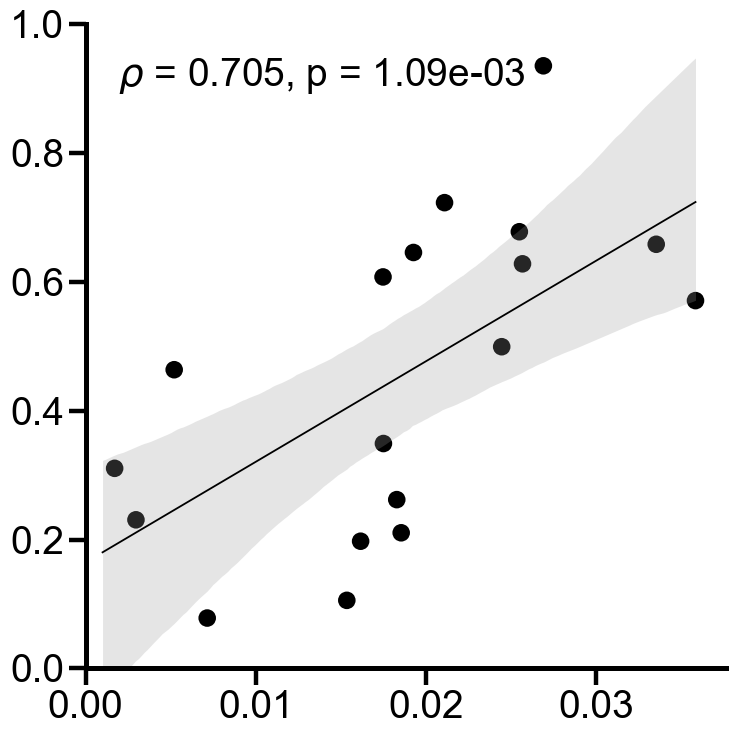

{'rho': 0.7048503611971104,
 'p': 0.0010886663167765575,
 'ci_low': 0.4225720861977099,
 'ci_high': 0.8437500000000002,
 'n': 18}

In [12]:
set_panel_style(scale=4)
point_rgb = (0.0, 0.0, 0.0)   # gray
line_rgb  = (0.0, 0.0, 0.0)   # black
band_rgb  = (0.6, 0.6, 0.6)   # gray band

selected_sector_index = 14

x = np.array([e[:, -1] for e in total_species_ei]).T[selected_sector_index].astype(float)
y = np.array([e[-1] for e in total_species_OD]).astype(float)

mask = np.isfinite(x) & np.isfinite(y)
x, y = x[mask], y[mask]

# Spearman
rho, p = spearmanr(x, y)

# OLS line + bootstrap CI
m, b = np.polyfit(x, y, deg=1)
xg = np.linspace(0.001, x.max(), 200)
yg = m * xg + b

B = 2000
rng = np.random.default_rng(0)
Yhat = np.empty((B, xg.size))
n = x.size
for i in range(B):
    idx = rng.integers(0, n, n)
    m_i, b_i = np.polyfit(x[idx], y[idx], deg=1)
    Yhat[i] = m_i * xg + b_i
lo, hi = np.percentile(Yhat, [2.5, 97.5], axis=0)

# Plot
fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(
    x, y,
    s=160,
    color=point_rgb,
    edgecolors="none"
)
ax.plot(xg, yg, linewidth=1.3, color=line_rgb)
ax.fill_between(xg, lo, hi, alpha=0.25, color=band_rgb, linewidth=0)

ax.text(
    0.05, 0.95,
    rf"$\rho$ = {rho:.3f}, p = {p:.2e}",
    transform=ax.transAxes,
    ha="left", va="top"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.set_xlim(0, 1.05 * x.max())
ax.set_ylim(0, 1.0)

plt.tight_layout()
#fig.savefig(f"Figure4_E{selected_sector_index}_harris.pdf", format="pdf", bbox_inches="tight", pad_inches=0.5)
plt.show()
spearman_ci(x, y)